Małgorzata Krętowska   
Wydział Informatyki PB 

# Uczenie maszynowe 1 
## Pracownia specjalistyczna 6
### Regresja liniowa

## Cele zajęć:
Po wykonaniu ćwiczeń student powinien potrafić wykonać:
- regresję liniową z jednym predyktorem,
- interpretację współczynników,
- ocenę dopasowania modelu,
- analizę reszt,
- regresję wieloraką,
- analizę predyktorów jakościowych,
- model z interakcją,
- model zawierający składnik $X^2$.

Dane są syntetyczne i zostały przygotowane wyłącznie do celów dydaktycznych.


## Zbiór danych: ceny używanych samochodów

Zmienną zależną jest `cena_pln`.

| Zmienna | Opis |
|---|---|
| `id` | identyfikator samochodu |
| `wiek_lata` | wiek samochodu w latach |
| `przebieg_tys_km` | przebieg w tysiącach kilometrów |
| `moc_km` | moc silnika w KM |
| `segment` | segment: miejski, kompakt, SUV |
| `paliwo` | benzyna, diesel, hybryda |
| `automat` | automatyczna skrzynia biegów: tak/nie |
| `cena_pln` | cena samochodu w PLN – zmienna zależna |


## Zadanie 1. Wczytanie i podstawowa analiza danych

1. Wczytaj zbiór danych.
2. Wyświetl pierwsze obserwacje.
3. Sprawdź liczbę wierszy i kolumn.
4. Sprawdź typy zmiennych.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

df = pd.read_csv("samochody_uzywane_regresja.csv")

display(df.head())

print("Wymiar zbioru:", df.shape)
print()
print(df.dtypes)


,id,wiek_lata,przebieg_tys_km,moc_km,segment,paliwo,automat,cena_pln
0,1,6.4,117.8,117,SUV,benzyna,tak,107100
1,2,2.2,8.3,113,kompakt,diesel,tak,114000
2,3,8.5,129.0,116,SUV,diesel,nie,93100
3,4,3.8,59.5,121,kompakt,hybryda,nie,106100
4,5,1.5,17.1,95,miejski,benzyna,tak,98400


Wymiar zbioru: (260, 8)

id                   int64
wiek_lata          float64
przebieg_tys_km    float64
moc_km               int64
segment                str
paliwo                 str
automat                str
cena_pln             int64
dtype: object


**Interpretacja:**  
Mamy 260 obserwacji. Zmienna `cena_pln` jest numeryczna i będzie zmienną zależną. W zbiorze występują zarówno predyktory numeryczne, jak i jakościowe.


## Zadanie 2. Regresja liniowa z jednym predyktorem

Sprawdźmy zależność między **wiekiem samochodu** a **ceną**.

Model:

$$cena = \beta_0 + \beta_1 \cdot wiek + \varepsilon$$

Najpierw narysujemy wykres punktowy i policzymy korelację.


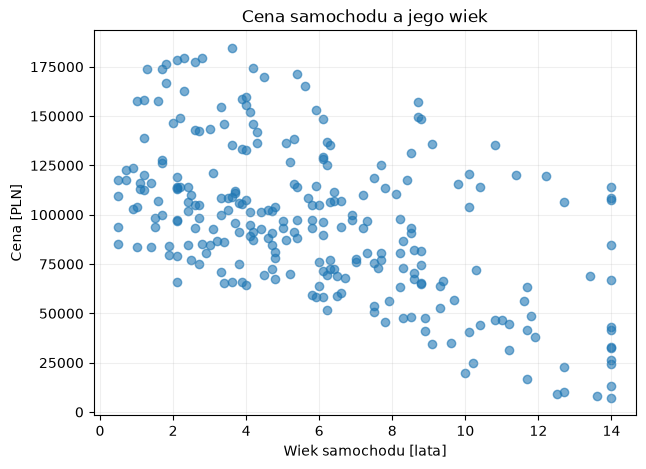

Korelacja r = -0.549


In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(df["wiek_lata"], df["cena_pln"], alpha=0.6)
plt.xlabel("Wiek samochodu [lata]")
plt.ylabel("Cena [PLN]")
plt.title("Cena samochodu a jego wiek")
plt.grid(alpha=0.2)
plt.show()

r = df["wiek_lata"].corr(df["cena_pln"])
print("Korelacja r =", round(r, 3))


Dopasujemy model metodą najmniejszych kwadratów.  
W `statsmodels` wygodnie możemy użyć zapisu formuły:

`cena_pln ~ wiek_lata`


In [4]:
model_1 = smf.ols(
    "cena_pln ~ wiek_lata",
    data=df
).fit()

print(model_1.summary())


                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.301
Model:                            OLS   Adj. R-squared:                  0.298
Method:                 Least Squares   F-statistic:                     111.1
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           7.71e-22
Time:                        12:27:21   Log-Likelihood:                -3063.0
No. Observations:                 260   AIC:                             6130.
Df Residuals:                     258   BIC:                             6137.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.305e+05   3802.791     34.310      0.0

In [5]:
b0 = model_1.params["Intercept"]
b1 = model_1.params["wiek_lata"]

print("b0 =", round(b0, 2))
print("b1 =", round(b1, 2))
print()
print(
    f"Model: cena = {b0:.2f} + ({b1:.2f}) * wiek"
)


b0 = 130473.81
b1 = -5788.72

Model: cena = 130473.81 + (-5788.72) * wiek


**Interpretacja współczynnika przy wieku:**  
$\hat{\beta}_1$ mówi, o ile przeciętnie zmienia się przewidywana cena samochodu, gdy jego wiek wzrasta o 1 rok.

W tym zbiorze współczynnik jest ujemny, więc starsze samochody mają przeciętnie niższą cenę.


## Zadanie 3. Prosta regresji i predykcja

Narysujmy dane oraz prostą regresji.


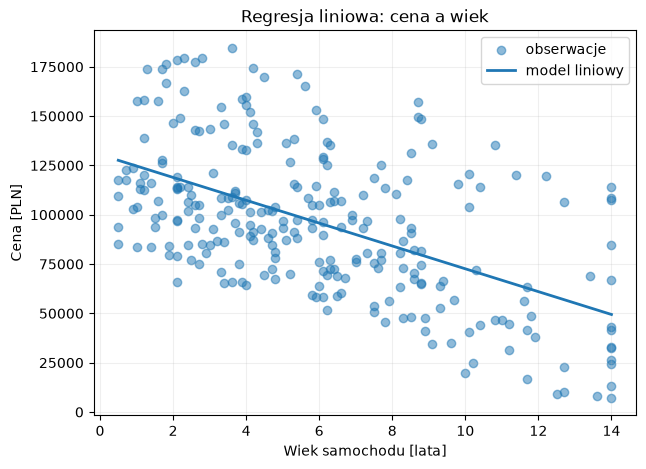

In [6]:
x = np.linspace(
    df["wiek_lata"].min(),
    df["wiek_lata"].max(),
    100
)

pred = pd.DataFrame({"wiek_lata": x})
y_pred = model_1.predict(pred)

plt.figure(figsize=(7, 5))
plt.scatter(
    df["wiek_lata"],
    df["cena_pln"],
    alpha=0.5,
    label="obserwacje"
)
plt.plot(
    x,
    y_pred,
    linewidth=2,
    label="model liniowy"
)

plt.xlabel("Wiek samochodu [lata]")
plt.ylabel("Cena [PLN]")
plt.title("Regresja liniowa: cena a wiek")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


Przewidźmy cenę samochodu mającego 5 lat.


In [7]:
nowy = pd.DataFrame({"wiek_lata": [5]})

prognoza = model_1.predict(nowy)

print("Przewidywana cena:", round(prognoza.iloc[0], 2), "PLN")


Przewidywana cena: 101530.2 PLN


## Zadanie 4. Ocena modelu i analiza reszt

Współczynnik determinacji:

$$R^2 = 1 - \frac{RSS}{TSS}$$

informuje, jaka część zmienności zmiennej zależnej jest wyjaśniana przez model.

Policzymy również:
- MAE – średni błąd bezwzględny,
- RMSE – pierwiastek średniego błędu kwadratowego.


In [8]:
y = df["cena_pln"]

y_hat = model_1.fittedvalues
reszty = model_1.resid

mae = np.mean(np.abs(reszty))
rmse = np.sqrt(np.mean(reszty**2))

print("R² =", round(model_1.rsquared, 3))
print("Skorygowany R² =", round(model_1.rsquared_adj, 3))
print("MAE =", round(mae, 2), "PLN")
print("RMSE =", round(rmse, 2), "PLN")


R² = 0.301
Skorygowany R² = 0.298
MAE = 25857.27 PLN
RMSE = 31633.92 PLN


### Wykres reszt vs. wartości przewidywane

Prawidłowy wykres reszt powinien przypominać losową chmurę punktów wokół 0.


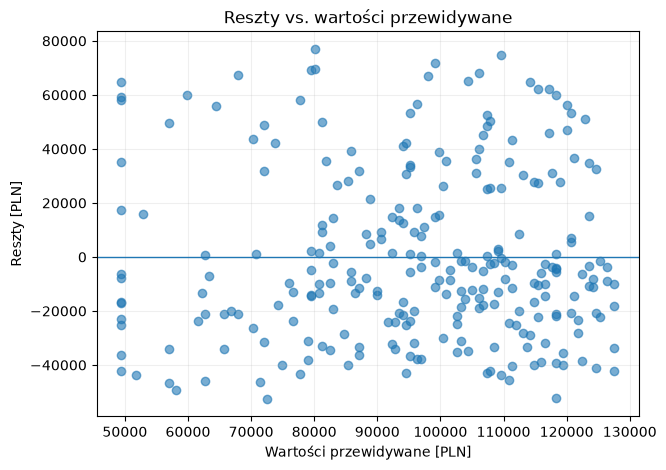

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(y_hat, reszty, alpha=0.6)
plt.axhline(0, linewidth=1)

plt.xlabel("Wartości przewidywane [PLN]")
plt.ylabel("Reszty [PLN]")
plt.title("Reszty vs. wartości przewidywane")
plt.grid(alpha=0.2)
plt.show()


**Pytanie**  
Czy na wykresie widzimy trend, krzywiznę, efekt lejka lub pojedyncze bardzo odstające obserwacje?


## Zadanie 5. Regresja wieloraka

Rozszerzymy model o trzy predyktory numeryczne:

- `wiek_lata`,
- `przebieg_tys_km`,
- `moc_km`.

Model:

$$cena = \beta_0 + \beta_1 \cdot wiek + \beta_2 \cdot przebieg + \beta_3 \cdot moc + \varepsilon$$

Najpierw sprawdzimy korelacje.


In [10]:
zmienne = [
    "wiek_lata",
    "przebieg_tys_km",
    "moc_km",
    "cena_pln"
]

corr = df[zmienne].corr()

display(corr.round(3))


,wiek_lata,przebieg_tys_km,moc_km,cena_pln
wiek_lata,1.000,0.725,-0.087,-0.549
przebieg_tys_km,0.725,1.000,0.028,-0.373
moc_km,-0.087,0.028,1.000,0.812
cena_pln,-0.549,-0.373,0.812,1.000


Zwróć uwagę, czy predyktory są ze sobą silnie skorelowane.  
Silna korelacja między predyktorami może utrudniać interpretację współczynników regresji.


In [11]:
model_2 = smf.ols(
    "cena_pln ~ wiek_lata + przebieg_tys_km + moc_km",
    data=df
).fit()

print(model_2.summary())


                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.895
Model:                            OLS   Adj. R-squared:                  0.893
Method:                 Least Squares   F-statistic:                     725.1
Date:                Tue, 17 Nov 2026   Prob (F-statistic):          8.95e-125
Time:                        12:27:22   Log-Likelihood:                -2817.0
No. Observations:                 260   AIC:                             5642.
Df Residuals:                     256   BIC:                             5656.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        4716.7531   3773.754     

In [12]:
print("R² modelu prostego =", round(model_1.rsquared, 3))
print("R² modelu wielorakiego =", round(model_2.rsquared, 3))
print(
    "Skorygowany R² modelu wielorakiego =",
    round(model_2.rsquared_adj, 3)
)


R² modelu prostego = 0.301
R² modelu wielorakiego = 0.895
Skorygowany R² modelu wielorakiego = 0.893


**Interpretacja:**  
W regresji wielorakiej współczynnik przy danym predyktorze interpretujemy **przy założeniu, że pozostałe predyktory są stałe**.

Na przykład współczynnik przy `moc_km` opisuje zmianę przewidywanej ceny związaną ze wzrostem mocy o 1 KM, przy takim samym wieku i przebiegu.


## Zadanie 6. Statystyka F – ocena całego modelu

Dla regresji wielorakiej test F sprawdza:

$$H_0: \beta_1 = \beta_2 = \beta_3 = 0$$

przeciwko hipotezie:

$$H_A: \text{przynajmniej jeden współczynnik jest różny od 0}$$

Wynik testu F znajduje się w podsumowaniu modelu.


In [13]:
print("F =", round(model_2.fvalue, 3))
print("p-value dla testu F =", model_2.f_pvalue)


F = 725.082
p-value dla testu F = 8.953387739094086e-125


Jeżeli `p-value < 0.05`, odrzucamy $H_0$ i uznajemy, że model jako całość jest istotny statystycznie.


## Zadanie 7. Predyktor jakościowy z dwoma poziomami

Sprawdźmy, czy cena różni się między samochodami z automatyczną i manualną skrzynią biegów.

Predyktor `automat` ma dwa poziomy:
- `nie`,
- `tak`.

Najpierw policzymy średnie ceny w obu grupach.


In [14]:
display(
    df.groupby("automat")["cena_pln"].mean().round(2)
)


automat
nie     87546.43
tak    106257.50
Name: cena_pln, dtype: float64

In [15]:
# Ustalamy kategorię bazową: "nie"
df["automat"] = pd.Categorical(
    df["automat"],
    categories=["nie", "tak"]
)

model_automat = smf.ols(
    "cena_pln ~ C(automat)",
    data=df
).fit()

print(model_automat.summary())

                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                  0.057
Method:                 Least Squares   F-statistic:                     16.69
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           5.87e-05
Time:                        12:27:22   Log-Likelihood:                -3101.4
No. Observations:                 260   AIC:                             6207.
Df Residuals:                     258   BIC:                             6214.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          8.755e+04   3111.17

W tym modelu:

- wyraz wolny to średnia cena samochodów **bez automatycznej skrzyni**,
- współczynnik `C(automat)[T.tak]` to różnica między średnią ceną samochodów z automatem i bez automatu.


## Zadanie 8. Predyktor jakościowy z więcej niż dwoma poziomami

Zmienna `segment` ma trzy poziomy:
- kompakt,
- miejski,
- SUV.

Przy trzech kategoriach potrzebujemy dwóch zmiennych dummy.  
Jako kategorię odniesienia przyjmiemy `kompakt`.


In [16]:
df["segment"] = pd.Categorical(
    df["segment"],
    categories=["kompakt", "miejski", "SUV"]
)

display(
    df.groupby("segment", observed=False)["cena_pln"].mean().round(2)
)

model_segment = smf.ols(
    "cena_pln ~ C(segment)",
    data=df
).fit()

print(model_segment.summary())


segment
kompakt     89219.83
miejski     62192.65
SUV        137221.05
Name: cena_pln, dtype: float64

                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.570
Model:                            OLS   Adj. R-squared:                  0.567
Method:                 Least Squares   F-statistic:                     170.3
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           7.93e-48
Time:                        12:27:22   Log-Likelihood:                -2999.9
No. Observations:                 260   AIC:                             6006.
Df Residuals:                     257   BIC:                             6016.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept              8.922e+

Interpretacja:

- `Intercept` – średnia cena samochodów kompaktowych,
- `C(segment)[T.miejski]` – różnica między segmentem miejskim i kompaktowym,
- `C(segment)[T.SUV]` – różnica między SUV i segmentem kompaktowym.


## Zadanie 9. Interakcja

Interakcja oznacza, że wpływ jednego predyktora zależy od wartości drugiego predyktora.

Sprawdzimy, czy wpływ wieku samochodu na cenę zależy od segmentu.

Model bez interakcji:

$$cena = \beta_0 + \beta_1 \cdot wiek + \beta_2 \cdot segment + \beta_3 \cdot moc + \varepsilon$$

Model z interakcją:

$$cena = \beta_0 + \beta_1 \cdot wiek + \beta_2 \cdot segment + \beta_3 \cdot wiek \cdot segment + \beta_4 \cdot moc + \varepsilon$$


In [17]:
model_bez_interakcji = smf.ols(
    "cena_pln ~ wiek_lata + C(segment) + moc_km",
    data=df
).fit()

model_interakcja = smf.ols(
    "cena_pln ~ wiek_lata * C(segment) + moc_km",
    data=df
).fit()

print(model_interakcja.summary())


                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.956
Model:                            OLS   Adj. R-squared:                  0.955
Method:                 Least Squares   F-statistic:                     924.2
Date:                Tue, 17 Nov 2026   Prob (F-statistic):          6.48e-169
Time:                        12:27:22   Log-Likelihood:                -2702.4
No. Observations:                 260   AIC:                             5419.
Df Residuals:                     253   BIC:                             5444.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

In [18]:
# Czy dodanie interakcji poprawia model?
F, p, df_diff = model_interakcja.compare_f_test(
    model_bez_interakcji
)

print("F =", round(F, 3))
print("p-value =", round(p, 5))


F = 11.591
p-value = 2e-05


Narysujemy linie przewidywane dla trzech segmentów.  
Dla czytelności utrzymamy moc na stałym poziomie 120 KM.


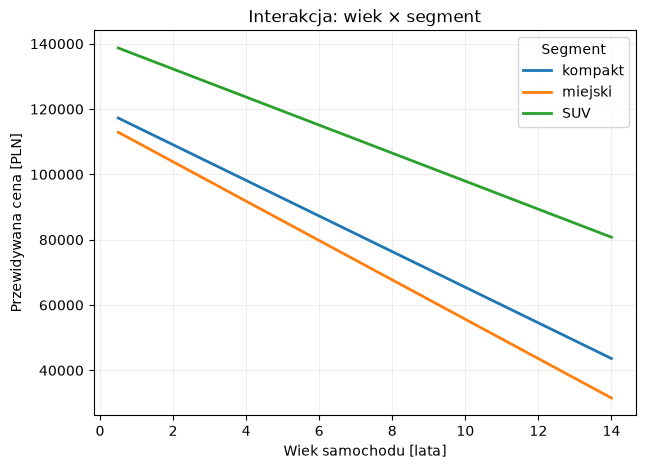

In [19]:
wiek_grid = np.linspace(
    df["wiek_lata"].min(),
    df["wiek_lata"].max(),
    100
)

plt.figure(figsize=(7, 5))

for segment_name in ["kompakt", "miejski", "SUV"]:

    dane_pred = pd.DataFrame({
        "wiek_lata": wiek_grid,
        "segment": segment_name,
        "moc_km": 120
    })

    cena_pred = model_interakcja.predict(dane_pred)

    plt.plot(
        wiek_grid,
        cena_pred,
        linewidth=2,
        label=segment_name
    )

plt.xlabel("Wiek samochodu [lata]")
plt.ylabel("Przewidywana cena [PLN]")
plt.title("Interakcja: wiek × segment")
plt.legend(title="Segment")
plt.grid(alpha=0.2)
plt.show()


Jeżeli linie nie są równoległe, oznacza to, że wpływ wieku na cenę jest różny w poszczególnych segmentach.


## Zadanie 10. Nieliniowy wpływ predyktora – składnik $X^2$

Model liniowy:

$$cena = \beta_0 + \beta_1 \cdot moc + \varepsilon$$

Model rozszerzony:

$$cena = \beta_0 + \beta_1 \cdot moc + \beta_2 \cdot moc^2 + \varepsilon$$

Mimo obecności $moc^2$ jest to nadal model liniowy względem parametrów $\beta$.


In [20]:
model_moc = smf.ols(
    "cena_pln ~ moc_km",
    data=df
).fit()

model_moc_x2 = smf.ols(
    "cena_pln ~ moc_km + I(moc_km**2)",
    data=df
).fit()

print(model_moc_x2.summary())


                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.666
Model:                            OLS   Adj. R-squared:                  0.664
Method:                 Least Squares   F-statistic:                     256.5
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           5.76e-62
Time:                        12:27:23   Log-Likelihood:                -2966.9
No. Observations:                 260   AIC:                             5940.
Df Residuals:                     257   BIC:                             5951.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       8689.7457   2.08e+04      0.

In [21]:
print("R² modelu bez X² =", round(model_moc.rsquared, 3))
print("R² modelu z X² =", round(model_moc_x2.rsquared, 3))

F, p, df_diff = model_moc_x2.compare_f_test(model_moc)

print("Test F porównujący modele:")
print("F =", round(F, 3))
print("p-value =", p)


R² modelu bez X² = 0.66
R² modelu z X² = 0.666
Test F porównujący modele:
F = 4.726
p-value = 0.030618688887133597


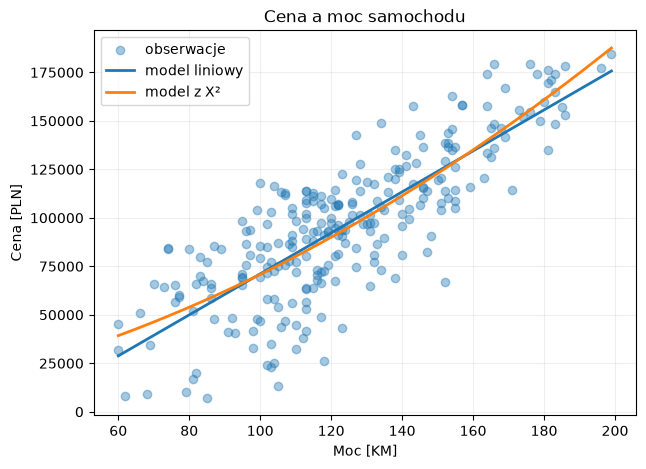

In [22]:
moc_grid = np.linspace(
    df["moc_km"].min(),
    df["moc_km"].max(),
    150
)

pred_moc = pd.DataFrame({"moc_km": moc_grid})

y_lin = model_moc.predict(pred_moc)
y_x2 = model_moc_x2.predict(pred_moc)

plt.figure(figsize=(7, 5))
plt.scatter(
    df["moc_km"],
    df["cena_pln"],
    alpha=0.4,
    label="obserwacje"
)
plt.plot(
    moc_grid,
    y_lin,
    linewidth=2,
    label="model liniowy"
)
plt.plot(
    moc_grid,
    y_x2,
    linewidth=2,
    label="model z X²"
)

plt.xlabel("Moc [KM]")
plt.ylabel("Cena [PLN]")
plt.title("Cena a moc samochodu")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


**Wniosek:**  
Test F pozwala sprawdzić, czy dodanie składnika $X^2$ istotnie poprawiło dopasowanie w porównaniu z prostszym modelem.


## Zadanie 11. Regresja prosta – przebieg

Zbadaj zależność między `przebieg_tys_km` i `cena_pln`.

1. Narysuj wykres punktowy.
2. Policz współczynnik korelacji.
3. Dopasuj model:

$$cena = \beta_0 + \beta_1 \cdot przebieg + \varepsilon$$

4. Podaj wartości $\hat{\beta}_0$ i $\hat{\beta}_1$.
5. Zinterpretuj $\hat{\beta}_1$.
6. Podaj $R^2$.


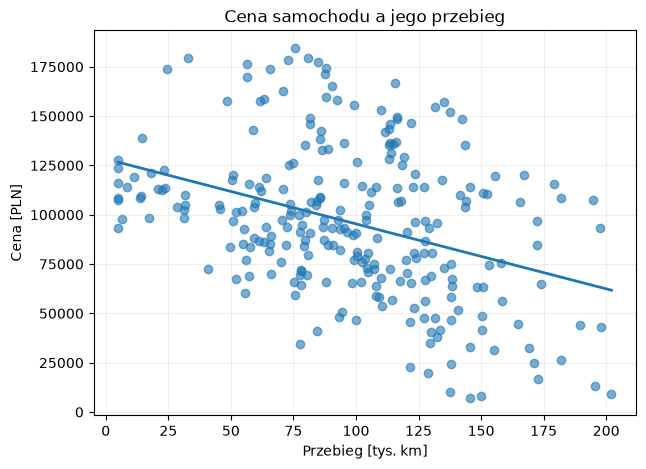

Korelacja r = -0.373

b0 = 128261.47
b1 = -329.18

R² = 0.139

Model: cena = 128261.47 + (-329.18) * przebieg_tys_km


In [46]:
# Miejsce na rozwiązanie zadania 11

model_3 = smf.ols(
    "cena_pln ~ przebieg_tys_km",
    data=df
).fit()

b0 = model_3.params["Intercept"]
b1 = model_3.params["przebieg_tys_km"]

x = np.linspace(
    df["przebieg_tys_km"].min(),
    df["przebieg_tys_km"].max(),
    100
)

pred = pd.DataFrame({"przebieg_tys_km": x})
y_pred = model_3.predict(pred)

plt.figure(figsize=(7, 5))
plt.scatter(df["przebieg_tys_km"], df["cena_pln"], alpha=0.6)
plt.xlabel("Przebieg [tys. km]")
plt.ylabel("Cena [PLN]")
plt.title("Cena samochodu a jego przebieg")
plt.plot(
    x,
    y_pred,
    linewidth=2,
    label="model liniowy"
)
plt.grid(alpha=0.2)
plt.show()

r = df["przebieg_tys_km"].corr(df["cena_pln"])
print("Korelacja r =", round(r, 3))
print()
print("b0 =", round(b0, 2))
print("b1 =", round(b1, 2))
print()
print("R² =", round(model_3.rsquared, 3))
print()
print(
    f"Model: cena = {b0:.2f} + ({b1:.2f}) * przebieg_tys_km"
)



## Zadanie 12. Diagnostyka modelu z zadania 11

Dla modelu `cena ~ przebieg`:

1. Oblicz wartości przewidywane i reszty.
2. Narysuj wykres `reszty vs. wartości przewidywane`.
3. Oceń, czy w resztach widoczny jest wyraźny wzorzec.
4. Oblicz MAE i RMSE.


MAE = 28625.56 PLN
RMSE = 35111.69 PLN


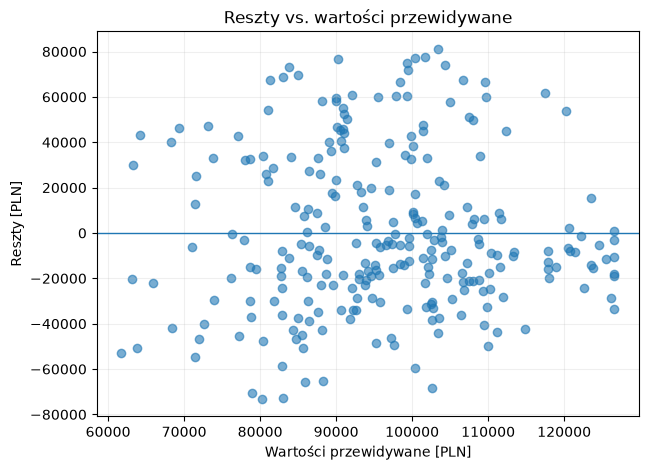

In [47]:
# Miejsce na rozwiązanie zadania 12

y = df["cena_pln"]

y_hat = model_3.fittedvalues
reszty = model_3.resid

mae = np.mean(np.abs(reszty))
rmse = np.sqrt(np.mean(reszty**2))

print("MAE =", round(mae, 2), "PLN")
print("RMSE =", round(rmse, 2), "PLN")

plt.figure(figsize=(7, 5))
plt.scatter(y_hat, reszty, alpha=0.6)
plt.axhline(0, linewidth=1)

plt.xlabel("Wartości przewidywane [PLN]")
plt.ylabel("Reszty [PLN]")
plt.title("Reszty vs. wartości przewidywane")
plt.grid(alpha=0.2)
plt.show()



## Zadanie 13. Regresja wieloraka

Zbuduj model:

$$cena = \beta_0 + \beta_1 \cdot wiek + \beta_2 \cdot moc + \varepsilon$$

1. Dopasuj model.
2. Zinterpretuj współczynnik przy `moc_km`.
3. Podaj $R^2$ i skorygowany $R^2$.
4. Porównaj $R^2$ z modelem wykorzystującym tylko `wiek_lata`.
5. Sprawdź wynik testu F dla całego modelu.


In [51]:
# Miejsce na rozwiązanie zadania 13
model_4 = smf.ols(
    "cena_pln ~ wiek_lata + moc_km",
    data=df
).fit()

b0 = model_4.params["Intercept"]
b1 = model_4.params["wiek_lata"]
b2 = model_4.params["moc_km"]

print(f"Model: cena = {b0:.2f} + ({b1:.2f}) * wiek_lata + ({b2:.2f}) * moc_km")
print()
print("R² =", round(model_4.rsquared, 3))
print("Skorygowany R² =", round(model_4.rsquared_adj, 3))
print()
print("F =", round(model_2.fvalue, 3))
print("p-value dla testu F =", model_4.f_pvalue)



Model: cena = 2256.28 + (-5081.71) * wiek_lata + (1002.35) * moc_km

R² = 0.89
Skorygowany R² = 0.889

F = 725.082
p-value dla testu F = 4.39071919270877e-124


## Zadanie 14. Korelacje między predyktorami

Dla zmiennych:

- `wiek_lata`,
- `przebieg_tys_km`,
- `moc_km`,
- `cena_pln`

utwórz macierz korelacji.

Odpowiedz:
1. Które dwa predyktory są ze sobą najsilniej skorelowane?
2. Dlaczego silna korelacja między predyktorami może utrudniać interpretację regresji wielorakiej?


In [52]:
# Miejsce na rozwiązanie zadania 14

zmienne = [
    "wiek_lata",
    "przebieg_tys_km",
    "moc_km",
    "cena_pln"
]

corr = df[zmienne].corr()

display(corr.round(3))



,wiek_lata,przebieg_tys_km,moc_km,cena_pln
wiek_lata,1.000,0.725,-0.087,-0.549
przebieg_tys_km,0.725,1.000,0.028,-0.373
moc_km,-0.087,0.028,1.000,0.812
cena_pln,-0.549,-0.373,0.812,1.000


## Zadanie 15. Predyktor jakościowy – paliwo

Zmienna `paliwo` ma trzy poziomy:

- benzyna,
- diesel,
- hybryda.

1. Ustaw `benzyna` jako kategorię bazową.
2. Dopasuj model `cena_pln ~ C(paliwo)`.
3. Podaj średnią cenę dla każdego rodzaju paliwa.
4. Zinterpretuj współczynniki dla diesla i hybrydy.
5. Sprawdź, które współczynniki są istotne statystycznie na poziomie 0.05.


In [54]:
# Miejsce na rozwiązanie zadania 15

df["paliwo"] = pd.Categorical(
    df["paliwo"],
    categories=["benzyna", "diesel", "hybryda"]
)

display(
    df.groupby("paliwo", observed=False)["cena_pln"].mean().round(2)
)

model_segment2 = smf.ols(
    "cena_pln ~ C(paliwo)",
    data=df
).fit()

print(model_segment2.summary())

paliwo
benzyna     81444.25
diesel     106973.08
hybryda    108120.29
Name: cena_pln, dtype: float64

                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.110
Method:                 Least Squares   F-statistic:                     16.99
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           1.18e-07
Time:                        13:00:32   Log-Likelihood:                -3093.5
No. Observations:                 260   AIC:                             6193.
Df Residuals:                     257   BIC:                             6204.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             8.144e+04 

## Zadanie 16. Interakcja

Zbuduj dwa modele:

**Model A – bez interakcji**

`cena_pln ~ wiek_lata + C(segment) + moc_km`

**Model B – z interakcją**

`cena_pln ~ wiek_lata * C(segment) + moc_km`

1. Porównaj $R^2$ obu modeli.
2. Porównaj modele testem F (`compare_f_test`).
3. Czy dodanie interakcji istotnie poprawia model?
4. Co oznacza interakcja `wiek × segment`?


In [58]:
# Miejsce na rozwiązanie zadania 16

model_bez_interakcji = smf.ols(
    "cena_pln ~ wiek_lata + C(segment) + moc_km",
    data=df
).fit()

model_interakcja = smf.ols(
    "cena_pln ~ wiek_lata * C(segment) + moc_km",
    data=df
).fit()

print("R² =", round(model_bez_interakcji.rsquared, 3))
print("R² =", round(model_interakcja.rsquared, 3))
print("Różnica = ", abs(round(model_bez_interakcji.rsquared - model_interakcja.rsquared, 3)))

R² = 0.952
R² = 0.956
Różnica =  0.004


## Zadanie 17. Składnik $X^2$

Sprawdź, czy zależność ceny od mocy jest lepiej opisana przez model zawierający $moc^2$.

Porównaj:

**Model A**

`cena_pln ~ moc_km`

**Model B**

`cena_pln ~ moc_km + I(moc_km**2)`

1. Podaj $R^2$ obu modeli.
2. Sprawdź `p-value` dla składnika `moc_km**2`.
3. Porównaj modele testem F.
4. Narysuj na jednym wykresie obie krzywe.
5. Który model wybierasz i dlaczego?


R² (moc) = 0.66
R² (moc**2) = 0.666
Test F porównujący modele:
F = 4.726
p-value = 0.030618688887133597


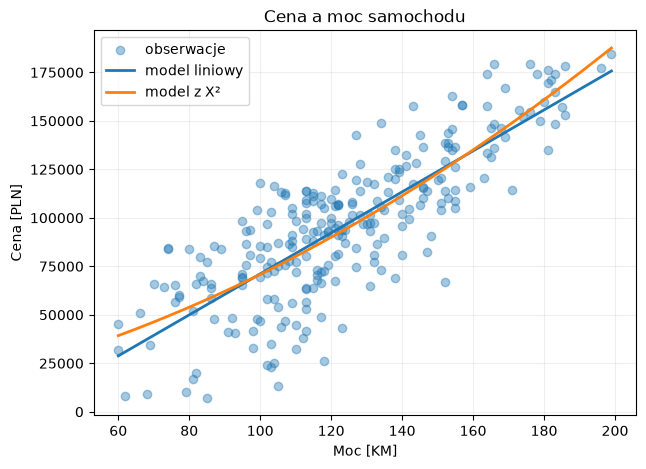

In [61]:
# Miejsce na rozwiązanie zadania 17

model_moc = smf.ols(
    "cena_pln ~ moc_km",
    data=df
).fit()

model_moc_x2 = smf.ols(
    "cena_pln ~ moc_km + I(moc_km**2)",
    data=df
).fit()

print("R² (moc) =", round(model_moc.rsquared, 3))
print("R² (moc**2) =", round(model_moc_x2.rsquared, 3))

F, p, df_diff = model_moc_x2.compare_f_test(model_moc)

print("Test F porównujący modele:")
print("F =", round(F, 3))
print("p-value =", p)

moc_grid = np.linspace(
    df["moc_km"].min(),
    df["moc_km"].max(),
    150
)

pred_moc = pd.DataFrame({"moc_km": moc_grid})

y_lin = model_moc.predict(pred_moc)
y_x2 = model_moc_x2.predict(pred_moc)

plt.figure(figsize=(7, 5))
plt.scatter(
    df["moc_km"],
    df["cena_pln"],
    alpha=0.4,
    label="obserwacje"
)
plt.plot(
    moc_grid,
    y_lin,
    linewidth=2,
    label="model liniowy"
)
plt.plot(
    moc_grid,
    y_x2,
    linewidth=2,
    label="model z X²"
)

plt.xlabel("Moc [KM]")
plt.ylabel("Cena [PLN]")
plt.title("Cena a moc samochodu")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## Zadanie 18. Podsumowanie

Zbuduj własny, niezbyt rozbudowany model ceny samochodu.

Wybierz **maksymalnie 4 składniki** spośród:
- wieku,
- przebiegu,
- mocy,
- segmentu,
- paliwa,
- automatycznej skrzyni biegów.

Następnie:

1. Podaj równanie/model.
2. Podaj $R^2$ i skorygowany $R^2$.
3. Sprawdź statystykę F.
4. Wybierz dwa współczynniki i je zinterpretuj.
5. Narysuj wykres reszt vs. wartości przewidywane.
6. Napisz 2–3 zdania podsumowania jakości modelu.


In [ ]:
# Miejsce na rozwiązanie zadania 18

zmienne = [
    "wiek_lata",
    "przebieg_tys_km",
    "moc_km",
    "paliwo",
    "cena_pln"
]

model = smf.ols(
    "cena_pln ~ wiek_lata + przebieg_tys_km + moc_km + C(paliwo)",
    data=df
).fit()

print(model.summary())



                            OLS Regression Results                            
Dep. Variable:               cena_pln   R-squared:                       0.911
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                     520.3
Date:                Tue, 17 Nov 2026   Prob (F-statistic):          3.33e-131
Time:                        13:13:31   Log-Likelihood:                -2795.0
No. Observations:                 260   AIC:                             5602.
Df Residuals:                     254   BIC:                             5623.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             2263.2964 

---

## Najważniejsze polecenia użyte na zajęciach

```python
smf.ols("Y ~ X", data=df).fit()
model.summary()
model.rsquared
model.rsquared_adj
model.fittedvalues
model.resid
model.compare_f_test(model_prostszy)
```

Zmienne jakościowe:

```python
smf.ols("Y ~ C(kategoria)", data=df).fit()
```

Interakcja:

```python
smf.ols("Y ~ X * C(kategoria)", data=df).fit()
```

Składnik $X^2$:

```python
smf.ols("Y ~ X + I(X**2)", data=df).fit()
```
